# USD SOFR Swap Flies: PCA Rich / Cheap

A rolling 3-factor PCA (level, slope, curvature) of the SOFR swap curve gives a "fair" curve each day. Whatever the factors can't explain is a per-tenor **residual** in bp:

- **Positive residual:** the tenor is **cheap** (its rate is above the fit).
- **Negative residual:** the tenor is **rich**.

Combining tenors into **flies** (2 × belly − short − long) turns those residuals into tradeable rich/cheap signals. Each signal is z-scored against its own history and backtested with simple entry and exit rules.

> **⚠ P&L excludes carry, roll-down and transaction costs.** All P&L figures are raw changes in the fly rate × size. Bid-offer on a 3-leg fly can be a large share of a 1–3bp move.
>
> **⚠ The data here is simulated.** It stands in for the kdb export, so every number below is a plumbing test of the code. It says nothing about real edge.

**Contents:** 1. Config · 2. Data · 3. Method · 4. PCA sanity checks · 5. No-look-ahead test · 6. Backtest results · 7. Charts · 8. In-sample vs out-of-sample · 9. Live snapshot · 10. Optional extras

## 1. Config

Every parameter lives here. Nothing below this cell should need editing to change the data source, windows or trade rules.

In [1]:
# ---------------- Data ----------------
data_source    = "simulated"                        # "simulated" = repo CSV | "work" = kdb export (stub in Section 2)
csv_path       = "sofr_swap_rates_simulated.csv"    # simulated daily levels (stand-in for the kdb CSV)
work_csv_path  = "PATH/TO/kdb_sofr_swaps.csv"       # <-- set this at work
tenors         = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 25, 30]   # years, 3y-30y only
anchors        = [3, 5, 10, 30]                     # tenors used to solve each day's factor scores
start_date     = "2022-01-01"                       # main sample starts here (no data before it is used)
max_ffill_days = 3                                  # forward-fill isolated gaps up to this many rows

# ---------------- PCA / signal ----------------
pca_window     = 252     # days of past daily changes used to estimate the loadings
z_window       = 252     # days of past fly residuals used for the z-score
n_factors      = 3       # level, slope, curvature
refit_every    = 1       # refit loadings every N days (1 = daily)

# ---------------- Trade rules ----------------
entry_z        = 2.0     # enter when |z| >= entry_z
exit_z         = 0.0     # exit when z crosses back through this level
stop_z         = 3.5     # stop out when |z| >= stop_z
time_stop_days = 20      # max holding period (business days, execution to execution)
exec_lag       = 1       # signal at close of d, trade at close of d + exec_lag
size_usd_per_bp = 10_000 # fixed $ per bp of fly-rate move, every trade
fly_list       = [(3, 4, 5), (4, 5, 6), (5, 6, 7), (5, 7, 10), (7, 8, 9), (8, 9, 10),
                  (10, 11, 12), (10, 12, 15), (10, 15, 20), (10, 20, 30), (20, 25, 30)]
                         # (short, belly, long) flies to analyse; None = every combo with long <= max_wing_ratio * short
max_wing_ratio = 4       # only used when fly_list is None
fly_weighting  = "equal" # "equal" = 2*belly - short - long (PCA-neutral version is a stub at the end)

# ---------------- Evaluation ----------------
oos_split      = None    # None = midpoint of the signal sample; or a date string like "2025-01-01"
n_top          = 3       # number of flies picked in-sample for the out-of-sample test
min_trades_is  = 3       # a fly needs at least this many in-sample trades to be picked
seed           = 7       # seeds the random day used in the no-look-ahead test
demo_short_history = False   # True = keep only the last ~1y of rows to preview the insufficient-history mode

In [2]:
import itertools
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Chart style: validated colour-blind-safe categorical order, recessive grid
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
C_RED, C_GREY, C_INK, C_MUTED = "#e34948", "#b8b7b0", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 100, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelcolor": C_MUTED,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED, "legend.frameon": False,
})

assert set(anchors) <= set(tenors), "every anchor must be in the tenor list"
assert len(anchors) >= n_factors, "need at least as many anchors as factors to solve the scores"

## 2. Data

`load_curve()` is the **only** place data is read. It returns a DataFrame with dates as the index, tenors in years as the columns (`3, 4, … 30`) and **rates in bp**. Its steps:

1. **Read** the configured source: the repo CSV, or the work kdb export via the stub below.
2. **Parse column labels** like `"3y"` into tenor years and keep the configured tenors.
3. **Detect units.** If the median |rate| is below 25 the data is in percent and is multiplied by 100. Otherwise it is treated as bp already.
4. **Clean gaps.** Duplicate dates are removed (keeping the last), rows that are entirely empty are dropped, isolated gaps are forward-filled for up to `max_ffill_days` rows, and any row still incomplete is dropped. Holidays are *not* re-inserted, since a missing trading day isn't a gap.

To switch sources later:

- **Work CSV:** set `data_source = "work"` and fill in `_read_work_csv()`.
- **Live quotes:** fill in `BridgeSource.latest()`. Section 9 consumes it.

In [3]:
print("CSV files found in the repo:", sorted(glob.glob("*.csv")))
raw_peek = pd.read_csv(csv_path, index_col=0, nrows=5)
print(f"\nRaw file preview ({csv_path}): columns = {list(raw_peek.columns)}")
raw_peek

CSV files found in the repo: ['sofr_swap_rates_simulated.csv']

Raw file preview (sofr_swap_rates_simulated.csv): columns = ['3y', '4y', '5y', '6y', '7y', '8y', '9y', '10y', '11y', '12y', '13y', '14y', '15y', '20y', '25y', '30y']


,3y,4y,5y,6y,7y,8y,9y,10y,11y,12y,13y,14y,15y,20y,25y,30y
date,,,,,,,,,,,,,,,,
2016-01-04,1.2543,1.4666,1.6101,1.7212,1.7967,1.8582,1.9032,1.9470,1.9734,1.9963,2.0139,2.0235,2.0327,2.0632,2.0604,2.0557
2016-01-05,1.2901,1.4976,1.6371,1.7431,1.8067,1.8793,1.9286,1.9634,1.9937,2.0124,2.0206,2.0232,2.0506,2.0535,2.0596,2.0486
2016-01-06,1.3763,1.5705,1.6862,1.7953,1.8518,1.9102,1.9609,1.9822,2.0059,2.0228,2.0353,2.0423,2.0586,2.0687,2.0595,2.0537
2016-01-07,1.3865,1.5825,1.6940,1.8045,1.8549,1.9224,1.9794,1.9905,2.0146,2.0220,2.0478,2.0391,2.0700,2.0685,2.0644,2.0430
2016-01-08,1.3139,1.5250,1.6405,1.7496,1.8254,1.8941,1.9378,1.9525,1.9897,2.0048,2.0175,2.0157,2.0430,2.0459,2.0586,2.0206


In [4]:
def _to_tenor_years(label):
    # "3y" / "3Y" / "3" / 3 -> 3 (int when whole, else float)
    v = float(str(label).strip().lower().rstrip("y"))
    return int(v) if v.is_integer() else v


def _to_bp(df):
    # Detect units from the median absolute rate: swap rates in % are ~0-10, in bp ~0-1000.
    med = float(np.nanmedian(np.abs(df.values)))
    if med < 25:
        return df * 100.0, f"percent detected (median |rate| = {med:.2f}) -> converted to bp (x100)"
    return df.astype(float), f"bp detected (median |rate| = {med:.1f}) -> no conversion"


def _read_work_csv(path):
    # >>>>>>>>>>>>>>>>>>>>>>>>>>>>  WORK DATA STUB  <<<<<<<<<<<<<<<<<<<<<<<<<<<<
    # Adapt to the kdb export. Return: index = dates, one column per tenor
    # (labels like "3y", "3" or 3), values in % or bp (units are detected later).
    #
    # Wide export (date, 3y, 4y, ...):
    #   return pd.read_csv(path, index_col=0, parse_dates=True)
    #
    # Long export (date, tenor, rate):
    #   raw = pd.read_csv(path, parse_dates=["date"])
    #   return raw.pivot_table(index="date", columns="tenor", values="rate", aggfunc="last")
    raise NotImplementedError("Fill in _read_work_csv() for the kdb export format, or use data_source='simulated'.")


class BridgeSource:
    # >>>>>>>>>>>>>>>>>>>>>>>>>>>>  LIVE BRIDGE STUB  <<<<<<<<<<<<<<<<<<<<<<<<<<<<
    # latest() must return a pd.Series: index = tenors (3, "3y", ...), values = last price (% or bp).
    def latest(self) -> pd.Series:
        raise NotImplementedError("Wire BridgeSource.latest() to the live bridge (last price per tenor).")


class CsvReplaySource(BridgeSource):
    # Demo stand-in for the bridge: replays one historical row as if it were today's live quotes.
    def __init__(self, row):
        self.row = row.copy()

    def latest(self) -> pd.Series:
        return self.row.copy()


def load_curve() -> pd.DataFrame:
    # Read
    if data_source == "simulated":
        raw = pd.read_csv(csv_path, index_col=0, parse_dates=True)
    elif data_source == "work":
        raw = _read_work_csv(work_csv_path)
    else:
        raise ValueError(f"unknown data_source {data_source!r}")

    # Tenor labels -> years; keep configured tenors only
    raw = raw.rename(columns=_to_tenor_years)
    missing = [t for t in tenors if t not in raw.columns]
    if missing:
        raise ValueError(f"tenors missing from the data: {missing}")
    df = raw[tenors].apply(pd.to_numeric, errors="coerce")
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    # Units
    df, unit_note = _to_bp(df)

    # Gaps
    n_dupes = int(df.index.duplicated(keep="last").sum())
    df = df[~df.index.duplicated(keep="last")]
    n_missing = int(df.isna().sum().sum())
    empty_rows = df.isna().all(axis=1)
    df = df[~empty_rows]
    before_ffill = int(df.isna().sum().sum())
    df = df.ffill(limit=max_ffill_days)
    n_filled = before_ffill - int(df.isna().sum().sum())
    incomplete = df.isna().any(axis=1)
    df = df[~incomplete]

    print("load_curve():")
    print(f"  source      : {data_source} ({csv_path if data_source == 'simulated' else work_csv_path})")
    print(f"  units       : {unit_note}")
    print(f"  duplicates  : {n_dupes} duplicate dates removed (kept last)")
    print(f"  missing     : {n_missing} missing values; {int(empty_rows.sum())} empty rows dropped, "
          f"{n_filled} values forward-filled (<= {max_ffill_days} rows), {int(incomplete.sum())} incomplete rows dropped")
    print(f"  result      : {len(df)} rows x {df.shape[1]} tenors, {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}")
    df.index.name, df.columns.name = "date", "tenor"
    return df


curve_all = load_curve()
curve_all.tail(3).round(1)

load_curve():
  source      : simulated (sofr_swap_rates_simulated.csv)
  units       : percent detected (median |rate| = 2.65) -> converted to bp (x100)
  duplicates  : 0 duplicate dates removed (kept last)
  missing     : 0 missing values; 0 empty rows dropped, 0 values forward-filled (<= 3 rows), 0 incomplete rows dropped
  result      : 2608 rows x 16 tenors, 2016-01-04 to 2025-12-31


tenor,3,4,5,6,7,8,9,10,11,12,13,14,15,20,25,30
date,,,,,,,,,,,,,,,,
2025-12-29,379.7,391.3,398.4,406.5,406.1,408.3,411.7,414.4,414.5,412.0,411.6,411.2,411.4,410.2,399.5,395.5
2025-12-30,366.4,377.2,384.4,392.7,393.2,394.7,399.8,400.0,401.3,400.5,400.1,400.2,400.6,401.5,391.2,390.0
2025-12-31,364.7,377.6,384.5,394.3,397.1,398.6,401.0,403.5,403.0,403.9,404.3,403.6,403.8,404.6,396.0,395.0


### Main sample and history check

The main sample starts at `start_date`. **No data before it is used**, not even as warm-up, so the results reflect what a dataset starting on that date can support.

The full backtest needs at least `pca_window + z_window + 60` rows:

- `pca_window` days to estimate the first set of loadings,
- then `z_window` days of residuals before the first z-score exists,
- then 60 days to trade.

With less history (e.g. ~1y of work data), the backtest sections are **skipped automatically**. PCA diagnostics and the live snapshot still run, using shorter windows that fit the data.

Main sample: 1043 rows, 2022-01-03 to 2025-12-31
Enough history for the full backtest (needs >= 564 rows). Windows: pca_window=252, z_window=252.


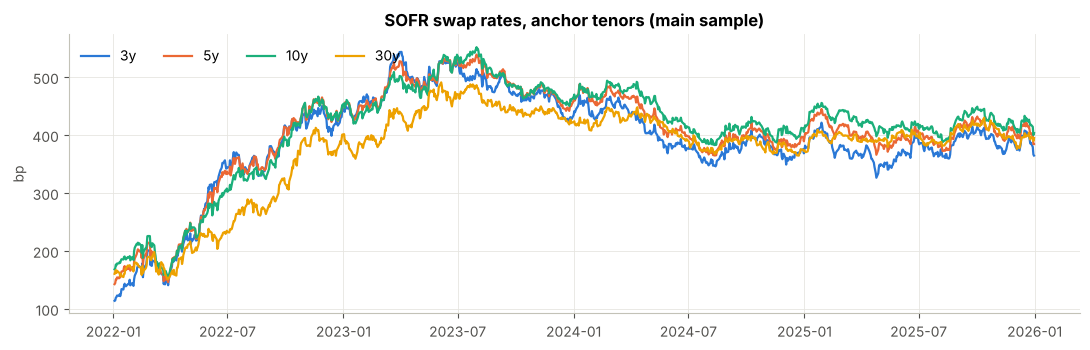

In [5]:
curve = curve_all.loc[start_date:].copy()
if demo_short_history:
    curve = curve.iloc[-260:]
    print("demo_short_history=True: kept only the last 260 rows to preview the insufficient-history mode.\n")

min_rows = pca_window + z_window + 60


def effective_windows(n_rows):
    # Full windows when history allows; otherwise the largest windows that still give today a z-score.
    # Today's z needs: pca_w + 1 rows before the first residual, then z_w past residuals -> pca_w + z_w <= n - 2.
    if n_rows >= pca_window + z_window + 60:
        return pca_window, z_window
    pca_w = min(pca_window, max(40, (n_rows - 2) // 2))
    z_w = min(z_window, n_rows - 2 - pca_w)
    if z_w < 20:
        raise ValueError(f"only {n_rows} rows: too short even for reduced windows")
    return pca_w, z_w


HAS_HISTORY = len(curve) >= min_rows
PCA_W, Z_W = effective_windows(len(curve))

print(f"Main sample: {len(curve)} rows, {curve.index[0]:%Y-%m-%d} to {curve.index[-1]:%Y-%m-%d}")
if HAS_HISTORY:
    print(f"Enough history for the full backtest (needs >= {min_rows} rows). "
          f"Windows: pca_window={PCA_W}, z_window={Z_W}.")
else:
    print("=" * 96)
    print(f"INSUFFICIENT HISTORY: {len(curve)} rows < pca_window + z_window + 60 = {min_rows}.")
    print("Backtest, results, charts and in-sample/out-of-sample sections will be SKIPPED.")
    print(f"Running PCA diagnostics and the live snapshot only, with REDUCED windows: "
          f"pca_window={PCA_W} (configured {pca_window}), z_window={Z_W} (configured {z_window}).")
    print("=" * 96)

fig, ax = plt.subplots(figsize=(11, 3.6))
for t, col in zip(anchors, [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]):
    ax.plot(curve.index, curve[t], color=col, label=f"{t}y")
ax.set_title("SOFR swap rates, anchor tenors (main sample)"); ax.set_ylabel("bp"); ax.legend(ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

## 3. Method

**No look-ahead.** On day *d*, anything *estimated* (loadings, window mean, z-score mean and std) uses data up to *d−1* only. Day *d*'s own levels are used only for *scoring*.

1. **Loadings.** Run PCA on daily changes (bp) over the `pca_window` days ending *d−1*. It uses the **covariance** matrix with no standardisation, so tenors keep their natural bp volatility. The top 3 eigenvectors are kept: level, slope and curvature.
2. **Demean.** Subtract the average curve over the same window from today's levels. This is a shift only, so values stay in bp.
3. **Scores.** Solve least squares of today's demeaned **anchor** levels (3y, 5y, 10y, 30y) on the anchor rows of the loadings to get 3 factor scores. That gives "how much level, slope and curvature today's anchors imply".
4. **Fit and residual.** For every tenor, fitted = its loading row × scores, and residual = demeaned actual − fitted (bp). **Positive = cheap, negative = rich.** Each day's residual uses the loadings that were live that day, which gives a point-in-time history. With 4 anchors and 3 factors, anchors can carry small residuals too.
5. **Flies.** Use the flies in `fly_list` (11 flies: 3s4s5s, 4s5s6s, 5s6s7s, 5s7s10s, 7s8s9s, 8s9s10s, 10s11s12s, 10s12s15s, 10s15s20s, 10s20s30s, 20s25s30s). The PCA itself still uses **all** tenors 3y–30y, so the fair curve is estimated from the full curve. Setting `fly_list = None` tests every short < belly < long with long ≤ `max_wing_ratio` × short instead.
   - **Fly residual** = 2 × belly − short − long, applied to the residuals. Positive means the belly is cheap vs its wings.
   - **Raw fly rate** = the same weights applied to the actual levels. P&L is measured on this.
6. **Signal.** Z-score each fly residual vs the mean and std of its previous `z_window` values (up to *d−1*).

Note that the equal-weight fly is **not** factor-neutral: its P&L also picks up some level, slope and curvature moves, not just the residual. A PCA-neutral weighting is a stub in Section 10.

In [6]:
def pca_loadings(changes, k):
    # Eigen-decompose the covariance (not correlation) of daily bp changes.
    cov = np.cov(changes, rowvar=False)
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1]                         # largest variance first
    return vecs[:, order[:k]], vals[order] / vals.sum()


def orient(E, cols):
    # Eigenvector signs are arbitrary. Flip them for DISPLAY only (residuals don't depend on sign):
    # PC1 positive on average, PC2 higher at the long end, PC3 positive in the belly vs the wings.
    E = E.copy()
    m = len(cols)
    belly = np.zeros(m); belly[m // 4: 3 * m // 4] = 1
    refs = [np.ones(m), np.linspace(-1, 1, m), belly - belly.mean()]
    for j in range(min(E.shape[1], 3)):
        if E[:, j] @ refs[j] < 0:
            E[:, j] *= -1
    return E


def pit_residuals(levels, pca_w, k=n_factors, anchor_list=anchors, refit=refit_every):
    # Point-in-time residuals: day d is scored with loadings and mean estimated on days d-pca_w .. d-1.
    X = levels.values
    dX = np.vstack([np.full(X.shape[1], np.nan), np.diff(X, axis=0)])   # dX[i] = X[i] - X[i-1]
    n, m = X.shape
    a_idx = [list(levels.columns).index(a) for a in anchor_list]

    resid = np.full((n, m), np.nan)
    scores = np.full((n, k), np.nan)
    explained = np.full((n, k), np.nan)
    E = mu = None
    first = pca_w + 1                                      # first day with a full window of changes
    for d in range(first, n):
        if E is None or (d - first) % refit == 0:
            win = slice(d - pca_w, d)                      # rows d-pca_w .. d-1: strictly before today
            E, ratio = pca_loadings(dX[win], k)
            mu = X[win].mean(axis=0)                       # window mean level (bp)
            explained[d] = ratio[:k]
        y = X[d] - mu                                      # today's levels, demeaned (a shift, still bp)
        s, *_ = np.linalg.lstsq(E[a_idx], y[a_idx], rcond=None)   # scores implied by the anchors
        scores[d] = s
        resid[d] = y - E @ s                               # actual minus 3-factor fit, every tenor
    idx = levels.index
    return (pd.DataFrame(resid, idx, levels.columns), pd.DataFrame(scores, idx, ["PC1", "PC2", "PC3"][:k]),
            pd.DataFrame(explained, idx, ["PC1", "PC2", "PC3"][:k]).dropna(), E)


def build_flies(tenor_list, flies=fly_list, max_ratio=max_wing_ratio, weighting=fly_weighting):
    # The configured fly_list, or (if None) all short < belly < long with long <= max_ratio * short.
    # Rows of W are the fly weights per tenor.
    if weighting != "equal":
        raise NotImplementedError("only fly_weighting='equal' is in the main flow (see the PCA-neutral stub)")
    if flies is None:
        combos = [c for c in itertools.combinations(tenor_list, 3) if c[2] <= max_ratio * c[0]]
    else:
        combos = sorted(tuple(f) for f in flies)
        bad = [f for f in combos if not (f[0] < f[1] < f[2]) or not set(f) <= set(tenor_list)]
        if bad:
            raise ValueError(f"flies must be short < belly < long with tenors from the tenor list: {bad}")
    names = [f"{s}s{b}s{l}s" for s, b, l in combos]
    W = pd.DataFrame(0.0, index=names, columns=tenor_list)
    for name, (s, b, l) in zip(names, combos):
        W.loc[name, [s, b, l]] = [-1.0, 2.0, -1.0]         # 2*belly - short - long
    meta = pd.DataFrame(combos, index=names, columns=["short", "belly", "long"])
    meta["width"] = meta["long"] - meta["short"]
    return W, meta


def rolling_z(series_df, z_w):
    # z on day d = (x_d - mean of x_{d-z_w..d-1}) / std of the same past window. shift(1) keeps day d out.
    mean = series_df.rolling(z_w, min_periods=z_w).mean().shift(1)
    std = series_df.rolling(z_w, min_periods=z_w).std().shift(1)
    return (series_df - mean) / std


def run_pipeline(levels, pca_w, z_w):
    # Everything the signal needs, from levels only. Used by the backtest, the look-ahead test and the live snapshot.
    resid, scores, explained, E_last = pit_residuals(levels, pca_w)
    W, meta = build_flies(list(levels.columns))
    fly_resid = resid @ W.T                                # 2*r_belly - r_short - r_long, bp
    fly_rate = levels @ W.T                                # 2*belly - short - long on actual rates, bp
    z = rolling_z(fly_resid, z_w)
    return dict(resid=resid, scores=scores, explained=explained, E_last=E_last,
                W=W, meta=meta, fly_resid=fly_resid, fly_rate=fly_rate, z=z)


out = run_pipeline(curve, PCA_W, Z_W)
resid, fly_resid, fly_rate, z, meta = out["resid"], out["fly_resid"], out["fly_rate"], out["z"], out["meta"]
signal_dates = z.dropna(how="all").index
print(f"Flies tested: {len(meta)} "
      + ("(from fly_list): " + ", ".join(meta.index) if fly_list is not None
         else f"(all short < belly < long from {len(tenors)} tenors with long <= {max_wing_ratio} x short)"))
print(f"Residuals from {resid.dropna().index[0]:%Y-%m-%d}; z-scores (signal sample) "
      + (f"from {signal_dates[0]:%Y-%m-%d} to {signal_dates[-1]:%Y-%m-%d} ({len(signal_dates)} days)"
         if len(signal_dates) else "not available"))

Flies tested: 11 (from fly_list): 3s4s5s, 4s5s6s, 5s6s7s, 5s7s10s, 7s8s9s, 8s9s10s, 10s11s12s, 10s12s15s, 10s15s20s, 10s20s30s, 20s25s30s
Residuals from 2022-12-22; z-scores (signal sample) from 2023-12-11 to 2025-12-31 (538 days)


## 4. PCA sanity checks

Before trusting any signal, check that the PCA looks like a rates PCA:

- **Variance explained.** On real data, expect roughly 90% / 6–9% / 1–3% for PC1 / PC2 / PC3.
- **Loading shapes.** Level should be roughly flat, slope should have opposite signs at the two ends, and curvature should have the belly against the wings.
- **Residuals.** They should be a few bp and centred near zero. The anchors (3y, 5y, 10y, 30y) show smaller residuals by construction, because the factor scores are solved on them.

Variance explained by each PC (rolling 252d windows of daily changes):


,average over time,latest window,typical on real data
PC1,88.4%,88.6%,~90%
PC2,7.2%,7.2%,6-9%
PC3,2.5%,1.9%,1-3%
total (3 PCs),98.1%,97.7%,~97-99%


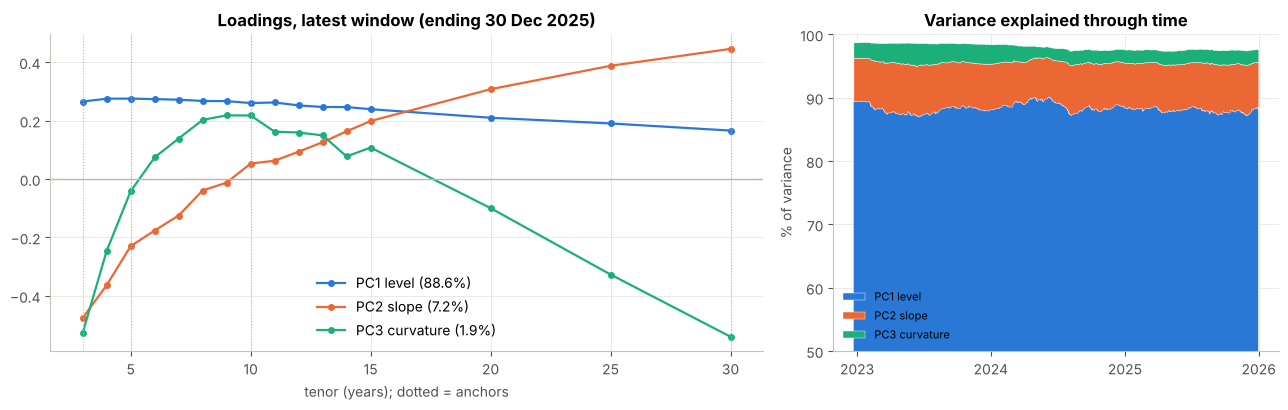

In [7]:
expl = out["explained"]
latest_expl = expl.iloc[-1]
print(f"Variance explained by each PC (rolling {PCA_W}d windows of daily changes):")
summary = pd.DataFrame({"average over time": expl.mean(), "latest window": latest_expl,
                        "typical on real data": ["~90%", "6-9%", "1-3%"][:n_factors]})
summary.loc["total (3 PCs)"] = [expl.sum(axis=1).mean(), latest_expl.sum(), "~97-99%"]
display(summary.style.format({"average over time": "{:.1%}", "latest window": "{:.1%}"}))

E_plot = orient(out["E_last"], tenors)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
labels = ["PC1 level", "PC2 slope", "PC3 curvature"]
for j, col in enumerate([C_BLUE, C_ORANGE, C_AQUA][:n_factors]):
    ax1.plot(tenors, E_plot[:, j], marker="o", ms=4, color=col, label=f"{labels[j]} ({latest_expl.iloc[j]:.1%})")
ax1.axhline(0, color=C_GREY, lw=1)
for a in anchors:
    ax1.axvline(a, color=C_GREY, lw=0.8, ls=":")
ax1.set_title(f"Loadings, latest window (ending {curve.index[-2]:%d %b %Y})")
ax1.set_xlabel("tenor (years); dotted = anchors"); ax1.legend()

ax2.stackplot(expl.index, (expl * 100).T.values, colors=[C_BLUE, C_ORANGE, C_AQUA][:n_factors],
              labels=labels[:n_factors], edgecolor="white", linewidth=0.3)
ax2.set_ylim(50, 100); ax2.set_ylabel("% of variance"); ax2.set_title("Variance explained through time")
ax2.legend(loc="lower left", fontsize=8); ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

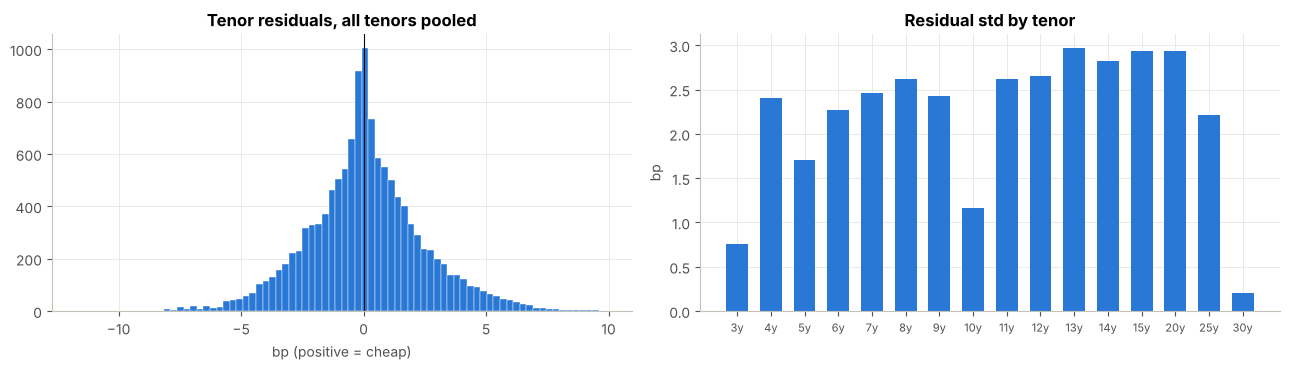

Units / centring checks
  [PASS] tenor residuals are bp-sized: pooled std = 2.36bp (percent units would be ~0.02, a units bug ~100s)
  [PASS] tenor residuals centred near zero: pooled mean = +0.08bp
  [PASS] fly residuals are bp-sized: pooled std = 5.28bp
  [PASS] fly residual means near zero: median |mean| across 11 flies = 0.46bp, worst = 1.42bp
  [PASS] fly rates are in bp: largest |fly rate| = 29.4bp


In [8]:
# Residual distribution and units checks
r = resid.dropna()
fr = fly_resid.dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.hist(r.values.ravel(), bins=80, color=C_BLUE, edgecolor="white", linewidth=0.3)
ax1.axvline(0, color=C_INK, lw=0.8)
ax1.set_title("Tenor residuals, all tenors pooled"); ax1.set_xlabel("bp (positive = cheap)")
ax2.bar([f"{t}y" for t in tenors], r.std(), color=C_BLUE, width=0.65)
ax2.set_title("Residual std by tenor"); ax2.set_ylabel("bp"); ax2.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

def check(name, ok, detail):
    print(f"  [{'PASS' if ok else 'WARN'}] {name}: {detail}")

print("Units / centring checks")
check("tenor residuals are bp-sized", 0.05 < r.values.std() < 25,
      f"pooled std = {r.values.std():.2f}bp (percent units would be ~0.02, a units bug ~100s)")
check("tenor residuals centred near zero", abs(r.values.mean()) < 1.0, f"pooled mean = {r.values.mean():+.2f}bp")
check("fly residuals are bp-sized", 0.05 < fr.values.std() < 50, f"pooled std = {fr.values.std():.2f}bp")
check("fly residual means near zero", fr.mean().abs().median() < 1.5,
      f"median |mean| across {fr.shape[1]} flies = {fr.mean().abs().median():.2f}bp, worst = {fr.mean().abs().max():.2f}bp")
check("fly rates are in bp", fly_rate.abs().values.max() > 1, f"largest |fly rate| = {fly_rate.abs().values.max():.1f}bp")

## 5. No-look-ahead test

The test picks a random day *d* in the signal sample and **cuts the data at *d*** (all later rows deleted). It reruns the whole pipeline on the truncated data and confirms that day *d*'s residuals and z-scores are identical to the full-data run. If anything used future data, they would differ.

In [9]:
rng = np.random.default_rng(seed)
# Pick d from the signal sample (so z is tested), excluding the last row so something is actually cut off.
# With short history the signal sample can be a single day; then test on days that have residuals.
first_resid = curve.index.get_loc(resid.dropna().index[0])
lo = curve.index.get_loc(signal_dates[0]) if len(signal_dates) > 1 else first_resid
if lo < len(curve) - 1:
    d_pos = int(rng.integers(lo, len(curve) - 1))
    d = curve.index[d_pos]
    trunc = run_pipeline(curve.iloc[: d_pos + 1], PCA_W, Z_W)
    z_full, z_trunc = z.loc[d], trunc["z"].loc[d]
    r_full, r_trunc = resid.loc[d], trunc["resid"].loc[d]
    max_dz = float((z_full - z_trunc).abs().fillna(0).max())   # NaN on both sides counts as equal
    max_dr = float((r_full - r_trunc).abs().max())
    assert np.allclose(z_full, z_trunc, atol=1e-9, equal_nan=True), "LOOK-AHEAD: z differs when future data is removed"
    assert np.allclose(r_full, r_trunc, atol=1e-9, equal_nan=True), "LOOK-AHEAD: residuals differ"
    print(f"[PASS] Truncated at {d:%Y-%m-%d} (row {d_pos} of {len(curve)}): {len(z_full)} fly z-scores and "
          f"{len(r_full)} tenor residuals identical (max |diff| z = {max_dz:.1e}, resid = {max_dr:.1e}bp)."
          + ("" if z_full.notna().any() else "  (z not yet available on this day: residuals tested)"))
else:
    print("Too few rows to truncate: look-ahead test skipped.")

[PASS] Truncated at 2025-11-19 (row 1012 of 1043): 11 fly z-scores and 16 tenor residuals identical (max |diff| z = 0.0e+00, resid = 0.0e+00bp).


## 6. Backtest

Each fly holds **one position at a time**:

- **Entry.** When flat, enter on the first day |z| ≥ `entry_z`.
  - z > 0: the belly is cheap, so **receive the belly / pay the wings**. This profits if the fly rate falls (direction +1).
  - z < 0: the belly is rich, so **pay the belly / receive the wings** (direction −1).
- **While in a trade,** further entry signals are ignored.
- **Exit** on the first of:
  - z crosses back through `exit_z`,
  - |z| ≥ `stop_z`,
  - `time_stop_days` business days after entry.

**Execution and P&L**

- Trades fill at the close of signal day + `exec_lag`, on the raw fly rate. The time stop is scheduled in advance, so it fills exactly `time_stop_days` after entry.
- Size is fixed at `size_usd_per_bp` per trade.
- Trade P&L (bp) = direction × (entry fly rate − exit fly rate). Dollars = bp × size.
- A daily mark-to-market series is built alongside. For every trade, the code **asserts** that the sum of its daily P&L equals its entry-minus-exit P&L.
- A trade still open at the end of the data is marked at the last close and flagged `open at end`.

In [10]:
def backtest_fly(zs, F):
    # zs, F: numpy arrays (z-score and raw fly rate) on the same dates. Returns (list of trades, daily bp P&L).
    n = len(zs)
    pnl = np.zeros(n)
    trades = []
    t = 0
    while t < n - exec_lag:
        zt = zs[t]
        if np.isnan(zt) or abs(zt) < entry_z:
            t += 1
            continue
        direction = 1 if zt > 0 else -1                   # +1 receive belly (cheap), -1 pay belly (rich)
        te = t + exec_lag                                   # entry fill
        if te >= n - 1:
            break
        tx = te + time_stop_days                            # scheduled time stop
        reason = "time stop"
        if tx > n - 1:
            tx, reason = n - 1, "open at end"
        exit_sig = None
        for s in range(t + 1, n):                           # look for an exit signal after the entry signal
            if s + exec_lag > tx:
                break                                       # time stop / data end comes first
            zv = zs[s]
            if np.isnan(zv):
                continue
            reverted = zv <= exit_z if direction > 0 else zv >= -exit_z
            if reverted or abs(zv) >= stop_z:
                tx, reason, exit_sig = s + exec_lag, ("reverted" if reverted else "stop"), s
                break
        trade_bp = direction * (F[te] - F[tx])
        daily = direction * (F[te:tx] - F[te + 1: tx + 1])  # day k P&L = dir * (F[k-1] - F[k]), k = te+1..tx
        pnl[te + 1: tx + 1] += daily
        assert np.isclose(daily.sum(), trade_bp), "daily MTM does not sum to entry-minus-exit P&L"
        trades.append(dict(signal_i=t, entry_i=te, exit_signal_i=exit_sig, exit_i=tx, direction=direction,
                           entry_z=zt, hold_days=tx - te, pnl_bp=trade_bp, exit_reason=reason))
        t = tx                                              # flat after the exit fill; a signal that day can re-enter
    return trades, pnl


def run_backtest(z_df, rate_df, dates):
    zz, FF = z_df.loc[dates], rate_df.loc[dates]
    all_trades, pnl = [], {}
    for fly in z_df.columns:
        tr, p = backtest_fly(zz[fly].values, FF[fly].values)
        for x in tr:
            x.update(fly=fly, signal_date=dates[x["signal_i"]], entry_date=dates[x["entry_i"]],
                     exit_date=dates[x["exit_i"]], entry_rate=FF[fly].values[x["entry_i"]],
                     exit_rate=FF[fly].values[x["exit_i"]])
        all_trades += tr
        pnl[fly] = p
    return pd.DataFrame(all_trades), pd.DataFrame(pnl, index=dates)


def half_life(x):
    # AR(1) on the fly residual: x_t = phi * x_{t-1} + e.  Half-life = -ln 2 / ln(phi) days.
    x = x.dropna().values
    if len(x) < 30:
        return np.nan
    x0, x1 = x[:-1] - x[:-1].mean(), x[1:] - x[1:].mean()
    phi = (x0 @ x1) / (x0 @ x0)
    return -np.log(2) / np.log(phi) if 0 < phi < 1 else np.nan


def fly_stats(trades_df, pnl_df, dates=None):
    # Per-fly stats over `dates` (default: all). Trades counted by entry date; P&L, Sharpe, drawdown from daily MTM.
    dates = pnl_df.index if dates is None else dates
    P = pnl_df.loc[dates]
    tr = trades_df[trades_df.entry_date.isin(dates)] if len(trades_df) else trades_df
    rows = {}
    for fly in pnl_df.columns:
        t = tr[tr.fly == fly] if len(tr) else tr
        p = P[fly]
        usd = p * size_usd_per_bp
        sd = p.std()
        rows[fly] = {
            "trades": len(t),
            "hit rate": (t.pnl_bp > 0).mean() if len(t) else np.nan,
            "avg hold (d)": t.hold_days.mean() if len(t) else np.nan,
            "net P&L (bp)": p.sum(),
            "net P&L ($)": usd.sum(),
            "Sharpe": p.mean() / sd * np.sqrt(252) if sd > 0 else np.nan,
            "max DD ($)": (usd.cumsum() - usd.cumsum().cummax()).min(),
        }
    return pd.DataFrame(rows).T


if HAS_HISTORY:
    trades, pnl_bp = run_backtest(z, fly_rate, signal_dates)
    # Each trade's P&L also equals the sum of its daily MTM, and the totals reconcile.
    assert np.isclose(trades.pnl_bp.sum(), pnl_bp.values.sum()), "trade P&L and daily MTM totals differ"
    print(f"{len(trades)} trades across {trades.fly.nunique()} of {len(meta)} flies, "
          f"{signal_dates[0]:%Y-%m-%d} to {signal_dates[-1]:%Y-%m-%d}.")
    print("[PASS] every trade's daily MTM sums to its entry-minus-exit P&L; trade and daily totals reconcile.")
    print("\nExit reasons:", trades.exit_reason.value_counts().to_dict())
else:
    print(f"SKIPPED (insufficient history: {len(curve)} rows < {min_rows}). See the message in Section 2.")

93 trades across 11 of 11 flies, 2023-12-11 to 2025-12-31.
[PASS] every trade's daily MTM sums to its entry-minus-exit P&L; trade and daily totals reconcile.

Exit reasons: {'time stop': 50, 'reverted': 37, 'stop': 6}


### Results by fly

In [11]:
if HAS_HISTORY:
    results = fly_stats(trades, pnl_bp)
    results["resid half-life (d)"] = [half_life(fly_resid.loc[signal_dates, f]) for f in results.index]
    results = results.join(meta[["short", "belly", "long", "width"]]).sort_values("Sharpe", ascending=False)
    traded = results[results.trades > 0]

    port = pnl_bp.sum(axis=1) * size_usd_per_bp
    print(f"Flies tested: {len(results)} | flies that traded: {len(traded)} | trades: {int(results.trades.sum())}")
    print(f"All flies combined (equal size): net P&L ${port.sum():,.0f}, "
          f"Sharpe {port.mean() / port.std() * np.sqrt(252):.2f}, hit rate {(trades.pnl_bp > 0).mean():.0%}")
    print("All flies by Sharpe:" if len(traded) <= 20 else "Top 15 and bottom 5 by Sharpe (full table in `results`):")

    cols = ["trades", "hit rate", "avg hold (d)", "net P&L (bp)", "net P&L ($)", "Sharpe", "max DD ($)", "resid half-life (d)"]
    shown = (traded if len(traded) <= 20 else pd.concat([traded.head(15), traded.tail(5)]))[cols]
    display(shown.style.format({"trades": "{:.0f}", "hit rate": "{:.0%}", "avg hold (d)": "{:.1f}",
                                "net P&L (bp)": "{:+.1f}", "net P&L ($)": "{:+,.0f}", "Sharpe": "{:.2f}",
                                "max DD ($)": "{:,.0f}", "resid half-life (d)": "{:.1f}"})
            .set_properties(subset=["Sharpe"], **{"font-weight": "bold"}))
else:
    print("SKIPPED (insufficient history).")

Flies tested: 11 | flies that traded: 11 | trades: 93
All flies combined (equal size): net P&L $4,166,000, Sharpe 3.75, hit rate 80%
All flies by Sharpe:


,trades,hit rate,avg hold (d),net P&L (bp),net P&L ($),Sharpe,max DD ($),resid half-life (d)
8s9s10s,6,100%,18.2,+61.2,"+612,100",1.69,"-50,800",6.9
3s4s5s,8,88%,14.5,+55.2,"+552,000",1.64,"-92,100",4.9
5s6s7s,11,82%,15.8,+50.9,"+508,900",1.41,"-99,800",9.0
5s7s10s,10,70%,14.1,+43.6,"+436,200",1.39,"-89,500",9.2
10s11s12s,9,89%,14.0,+43.5,"+435,000",1.39,"-94,700",5.7
10s12s15s,8,88%,16.6,+41.7,"+416,900",1.33,"-105,900",6.0
7s8s9s,10,90%,15.3,+39.5,"+395,500",1.28,"-79,900",11.1
4s5s6s,9,78%,17.0,+39.2,"+392,100",1.08,"-157,600",7.2
10s20s30s,6,67%,19.5,+18.4,"+183,600",0.62,"-151,200",14.6
20s25s30s,8,75%,12.1,+14.4,"+143,800",0.55,"-83,600",6.9


> **⚠ Net P&L here means net of nothing: carry, roll-down and transaction costs are all excluded.** "Net" only means the sum of winning and losing trades.
>
> A 3-leg fly crosses bid-offer on three swaps going in and three coming out. Carry and roll-down on a fly can easily be a few bp a month in either direction.
>
> The AR(1) half-life is computed on the fly residual over the whole signal sample. It is descriptive only and is not used for trading or selection.
>
> **On simulated data these numbers test the plumbing only.**

## 7. Charts

- **Sharpe by fly.** With a short fly list this is a ranked bar chart, which reads better than a mostly-empty grid. With `fly_list = None` it switches to a heatmap of belly tenor vs wing width (long − short), where each cell is the average Sharpe of the flies sharing it.
- **Equity curves** for the three highest-Sharpe flies.
- **One example trade,** showing the z-score with entry and exit, and the fly rate it was filled on.

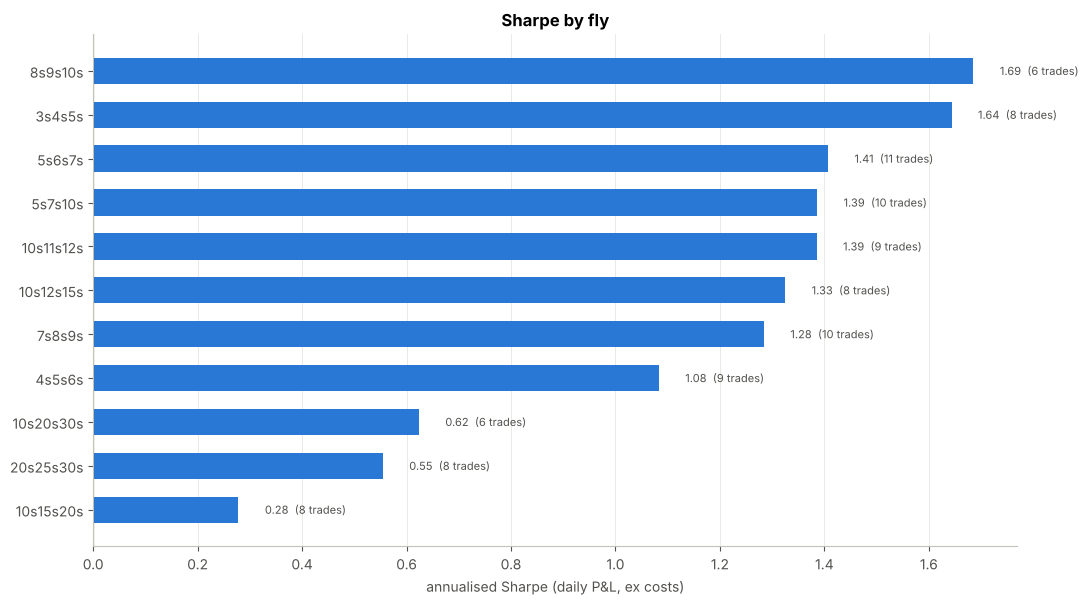

In [12]:
if HAS_HISTORY and len(traded) <= 30:
    sh = results["Sharpe"].sort_values()
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(sh) + 1.2))
    ax.barh(sh.index, sh.values, color=np.where(sh.values >= 0, C_BLUE, C_RED), height=0.6)
    ax.axvline(0, color=C_INK, lw=0.8)
    for i, (fly, v) in enumerate(sh.items()):
        n = int(results.loc[fly, "trades"])
        ax.text(v + (0.03 if v >= 0 else -0.03) * max(1, np.nanmax(np.abs(sh.values))), i,
                f"{v:.2f}  ({n} trades)", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=C_MUTED)
    ax.set_xlabel("annualised Sharpe (daily P&L, ex costs)"); ax.grid(axis="y", visible=False)
    ax.set_title("Sharpe by fly")
    plt.tight_layout(); plt.show()
elif HAS_HISTORY:
    hm = traded.pivot_table(index="belly", columns="width", values="Sharpe", aggfunc="mean").sort_index(ascending=False)
    lim = np.nanmax(np.abs(hm.values))
    fig, ax = plt.subplots(figsize=(13, 5.2))
    im = ax.imshow(hm.values, cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
    ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels([f"{w:g}" for w in hm.columns], fontsize=8)
    ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels([f"{b}y" for b in hm.index], fontsize=8)
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            v = hm.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5,
                        color="white" if abs(v) > 0.6 * lim else C_INK)
    ax.grid(False)
    ax.set_xlabel("wing width: long - short (years)"); ax.set_ylabel("belly")
    ax.set_title("Average Sharpe by belly and wing width (blue = positive, red = negative; blank = no fly)")
    fig.colorbar(im, ax=ax, pad=0.01, label="Sharpe")
    plt.tight_layout(); plt.show()
else:
    print("SKIPPED (insufficient history).")

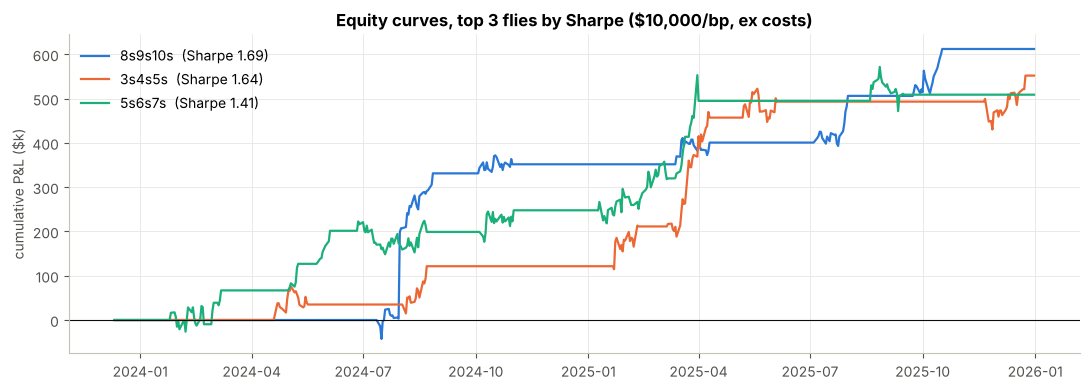

In [13]:
if HAS_HISTORY:
    top3 = traded.index[:3]
    fig, ax = plt.subplots(figsize=(11, 4))
    for fly, col in zip(top3, [C_BLUE, C_ORANGE, C_AQUA]):
        eq = (pnl_bp[fly] * size_usd_per_bp).cumsum()
        ax.plot(eq.index, eq.values / 1e3, color=col, label=f"{fly}  (Sharpe {traded.loc[fly, 'Sharpe']:.2f})")
    ax.axhline(0, color=C_INK, lw=0.8)
    ax.set_title(f"Equity curves, top 3 flies by Sharpe (${size_usd_per_bp:,.0f}/bp, ex costs)")
    ax.set_ylabel("cumulative P&L ($k)"); ax.legend(loc="upper left")
    plt.tight_layout(); plt.show()
else:
    print("SKIPPED (insufficient history).")

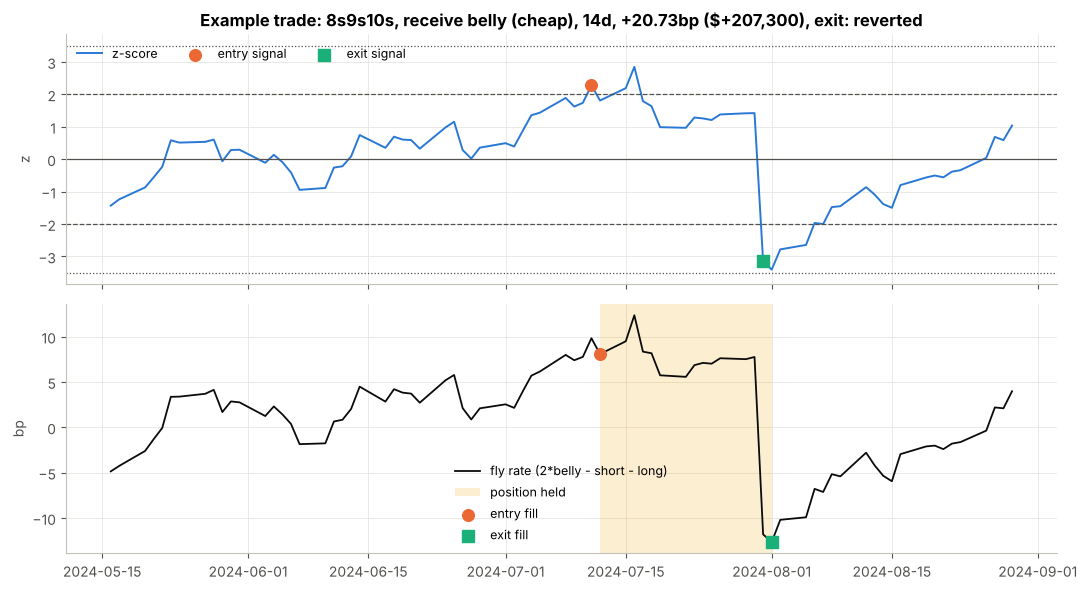

In [14]:
if HAS_HISTORY:
    ex_fly = traded.index[0]
    tf = trades[trades.fly == ex_fly]
    pick = tf[tf.exit_reason == "reverted"]
    ex = (pick if len(pick) else tf).loc[lambda d: d.pnl_bp.abs().idxmax()]   # clearest trade for this fly

    lo = max(ex.signal_i - 40, 0); hi = min(ex.exit_i + 20, len(signal_dates) - 1)
    win = signal_dates[lo: hi + 1]
    zz, FF = z.loc[win, ex_fly], fly_rate.loc[win, ex_fly]
    side = "receive belly (cheap)" if ex.direction > 0 else "pay belly (rich)"

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
    ax1.plot(zz.index, zz.values, color=C_BLUE, lw=1.4, label="z-score")
    for lvl, ls, lab in [(entry_z, "--", "entry"), (stop_z, ":", "stop"), (exit_z, "-", "exit")]:
        ax1.axhline(lvl, color=C_MUTED, lw=0.9, ls=ls)
        if lvl:
            ax1.axhline(-lvl, color=C_MUTED, lw=0.9, ls=ls)
    ax1.scatter([ex.signal_date], [ex.entry_z], s=70, color=C_ORANGE, zorder=5, label="entry signal")
    if ex.exit_signal_i is not None and not pd.isna(ex.exit_signal_i):
        sd = signal_dates[int(ex.exit_signal_i)]
        ax1.scatter([sd], [z.loc[sd, ex_fly]], s=70, color=C_AQUA, marker="s", zorder=5, label="exit signal")
    ax1.set_ylabel("z"); ax1.legend(loc="upper left", ncol=3, fontsize=9)
    ax1.set_title(f"Example trade: {ex_fly}, {side}, {ex.hold_days}d, {ex.pnl_bp:+.2f}bp "
                  f"(${ex.pnl_bp * size_usd_per_bp:+,.0f}), exit: {ex.exit_reason}")

    ax2.plot(FF.index, FF.values, color=C_INK, lw=1.3, label="fly rate (2*belly - short - long)")
    ax2.axvspan(ex.entry_date, ex.exit_date, color=C_YELLOW, alpha=0.18, lw=0, label="position held")
    ax2.scatter([ex.entry_date], [ex.entry_rate], s=70, color=C_ORANGE, zorder=5, label="entry fill")
    ax2.scatter([ex.exit_date], [ex.exit_rate], s=70, color=C_AQUA, marker="s", zorder=5, label="exit fill")
    ax2.set_ylabel("bp"); ax2.legend(loc="best", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("SKIPPED (insufficient history).")

## 8. In-sample vs out-of-sample

When several flies are tested, the best in-sample Sharpe is partly **selection luck**: some flies look great just by chance. The honest check is to pick the top flies using the **first half only**, then look at how those *same* flies did in the **second half**, which played no part in picking them. Expect the out-of-sample numbers to shrink towards the average fly. If they collapse to zero or below, the in-sample ranking was mostly noise.

- **Split:** `oos_split`, defaulting to the midpoint of the signal sample.
- **Trades** are counted in the half where they were entered.
- **Daily P&L** of a trade that straddles the split is assigned to each half day by day.

In [15]:
if HAS_HISTORY:
    split = pd.Timestamp(oos_split) if oos_split else signal_dates[len(signal_dates) // 2]
    is_dates, oos_dates = signal_dates[signal_dates < split], signal_dates[signal_dates >= split]
    st_is, st_oos = fly_stats(trades, pnl_bp, is_dates), fly_stats(trades, pnl_bp, oos_dates)

    eligible = st_is[st_is.trades >= min_trades_is].sort_values("Sharpe", ascending=False)
    picks = eligible.index[:n_top]
    oos_rank = st_oos["Sharpe"].rank(ascending=False)

    cols = ["trades", "hit rate", "net P&L (bp)", "Sharpe"]
    side_by_side = pd.concat({f"in-sample (to {split:%Y-%m-%d})": st_is.loc[picks, cols],
                              f"out-of-sample (from {split:%Y-%m-%d})": st_oos.loc[picks, cols]}, axis=1)
    side_by_side[("", "OOS rank")] = [f"{int(oos_rank[f])} / {len(st_oos)}" for f in picks]
    print(f"In-sample: {len(is_dates)} days | out-of-sample: {len(oos_dates)} days | "
          f"top {n_top} picked in-sample from {len(eligible)} flies with >= {min_trades_is} trades")
    fmt = {}
    for c in side_by_side.columns:
        fmt[c] = {"trades": "{:.0f}", "hit rate": "{:.0%}", "net P&L (bp)": "{:+.1f}", "Sharpe": "{:.2f}"}.get(c[1], "{}")
    display(side_by_side.style.format(fmt))

    summ = pd.DataFrame({
        "in-sample": [st_is.loc[picks, "Sharpe"].mean(), st_is["Sharpe"].median()],
        "out-of-sample": [st_oos.loc[picks, "Sharpe"].mean(), st_oos["Sharpe"].median()]},
        index=[f"top {n_top} picks: mean Sharpe", "all flies: median Sharpe"])
    display(summ.style.format("{:.2f}"))
else:
    print("SKIPPED (insufficient history).")

In-sample: 269 days | out-of-sample: 269 days | top 3 picked in-sample from 10 flies with >= 3 trades


,in-sample,out-of-sample
top 3 picks: mean Sharpe,1.90,0.89
all flies: median Sharpe,1.46,1.10


## 9. Live snapshot

`score_today(history_df, latest_quotes)` is the function to point at the bridge. It:

1. **Appends** today's quotes (any of %, bp, `"3y"` or `3` labels; units are detected) as a new row after the history.
2. **Refits** loadings on data **up to yesterday**, the same point-in-time pipeline as the backtest, so today's numbers match what the backtest would have seen.
3. **Prints** today's residual per tenor and every fly beyond ±`entry_z`σ, with z, the fly residual in bp and the implied trade direction.

If the history is shorter than the full requirement, it uses reduced windows and says so.

**Demo below.** `CsvReplaySource` replays one historical day as if it were live: the history is every row before that day, and the quotes are that day's row, sent in percent to exercise unit detection.

- The replayed day is the most recent one with at least one fly beyond ±`entry_z`, so the table isn't empty. In short-history mode it is the last row.
- Because the inputs are the same, the output must match the backtest pipeline's numbers for that day, and the code checks that it does.

At work, call `score_today(curve, BridgeSource().latest())`.

In [16]:
def score_today(history_df, latest_quotes, as_of=None, verbose=True):
    # Today's rich/cheap from history (up to yesterday) + today's quotes. Returns residuals, fly table and z.
    q = pd.Series(latest_quotes, dtype=float).rename(index=_to_tenor_years).reindex(history_df.columns)
    if q.isna().any():
        raise ValueError(f"latest quotes missing tenors: {list(q.index[q.isna()])}")
    q_bp, unit_note = _to_bp(q.to_frame().T)
    if as_of is None:
        as_of = pd.Timestamp.today().normalize()
        if as_of <= history_df.index[-1]:
            as_of = history_df.index[-1] + pd.offsets.BDay(1)
    q_bp.index = [pd.Timestamp(as_of)]
    levels = pd.concat([history_df, q_bp])

    pca_w, z_w = effective_windows(len(levels))
    res = run_pipeline(levels, pca_w, z_w)           # loadings for today use rows up to yesterday only
    today = levels.index[-1]
    r_today, fr_today, z_today = res["resid"].loc[today], res["fly_resid"].loc[today], res["z"].loc[today]

    flies = pd.DataFrame({"z": z_today, "fly resid (bp)": fr_today, "fly rate (bp)": res["fly_rate"].loc[today]})
    flies = flies[flies.z.abs() >= entry_z].reindex(flies.z.abs().sort_values(ascending=False).index).dropna()
    flies["direction"] = np.where(flies.z > 0, "RECEIVE belly / pay wings (belly cheap)",
                                  "PAY belly / receive wings (belly rich)")

    if verbose:
        print(f"Live snapshot for {today:%Y-%m-%d}  |  quotes: {unit_note}")
        reduced = (pca_w, z_w) != (pca_window, z_window)
        print(f"Loadings fitted on {pca_w} days of changes ending {levels.index[-2]:%Y-%m-%d}; z vs past {z_w} fly residuals"
              + ("  [REDUCED windows: short history]" if reduced else ""))
        tbl = pd.DataFrame({"rate (bp)": q_bp.iloc[0], "residual (bp)": r_today})
        tbl["view"] = np.where(r_today > 0, "cheap", "rich")
        print("\nTenor residuals (positive = cheap):")
        print(tbl.T.to_string(float_format=lambda v: f"{v:.1f}"))
        print(f"\nFlies beyond +/-{entry_z:g} sigma: {len(flies)} of {len(z_today)}")
        if len(flies):
            print(flies.to_string(float_format=lambda v: f"{v:+.2f}"))
    return dict(resid=r_today, flies=flies, z=z_today, windows=(pca_w, z_w))


# --- Demo: replay a historical day as "live" (at work: latest = BridgeSource().latest()) ---
# Use the most recent day with at least one fly beyond +/-entry_z so the output has something to show.
# In short-history mode use the last row, so the reduced windows match the diagnostics above.
has_sig = z.abs().ge(entry_z).any(axis=1)
demo_day = has_sig[has_sig].index[-1] if (HAS_HISTORY and has_sig.any()) else curve.index[-1]
pos = curve.index.get_loc(demo_day)

source = CsvReplaySource(curve.iloc[pos] / 100)   # sent in PERCENT, as a bridge might, to exercise unit detection
latest = source.latest()
live = score_today(curve.iloc[:pos], latest, as_of=demo_day)

# Consistency: same inputs and windows -> the live function must reproduce the pipeline's z for that day
if live["windows"] == (PCA_W, Z_W):
    assert np.allclose(live["z"].values, z.loc[demo_day].values, atol=1e-9, equal_nan=True)
    print(f"\n[PASS] score_today() matches the backtest pipeline's z-scores for {demo_day:%Y-%m-%d}.")

Live snapshot for 2025-12-09  |  quotes: percent detected (median |rate| = 4.06) -> converted to bp (x100)
Loadings fitted on 252 days of changes ending 2025-12-08; z vs past 252 fly residuals

Tenor residuals (positive = cheap):
tenor            3     4      5     6     7     8      9     10    11    12    13     14     15     20     25     30
rate (bp)     379.3 388.0  399.9 404.8 406.3 408.6  412.9 410.0 409.1 409.7 405.6  405.9  406.4  402.8  391.6  381.7
residual (bp)  -0.8  -4.1    1.7  -0.2  -1.7  -1.2    1.2  -1.2  -0.4  -0.9  -3.0    0.4    0.6    1.7    4.5    0.2
view           rich  rich  cheap  rich  rich  rich  cheap  rich  rich  rich  rich  cheap  cheap  cheap  cheap  cheap

Flies beyond +/-2 sigma: 1 of 11
              z  fly resid (bp)  fly rate (bp)                                direction
20s25s30s +2.12           +7.15          -1.22  RECEIVE belly / pay wings (belly cheap)

[PASS] score_today() matches the backtest pipeline's z-scores for 2025-12-09.


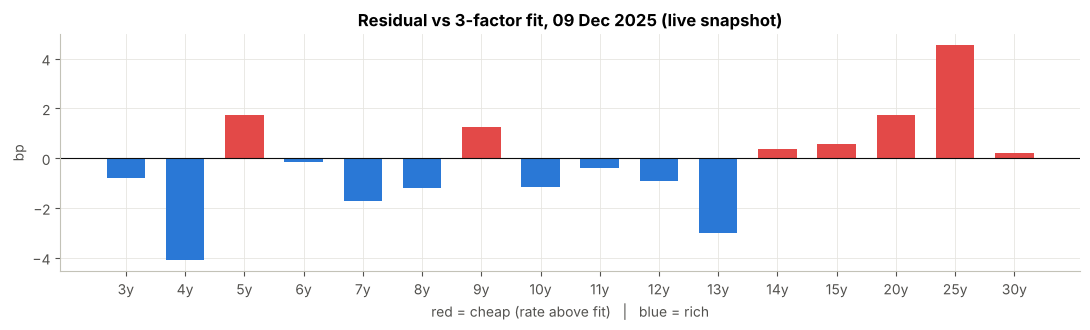

In [17]:
r_live = live["resid"]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar([f"{t}y" for t in r_live.index], r_live.values, color=np.where(r_live >= 0, C_RED, C_BLUE), width=0.65)
ax.axhline(0, color=C_INK, lw=0.8)
ax.set_title(f"Residual vs 3-factor fit, {demo_day:%d %b %Y} (live snapshot)")
ax.set_ylabel("bp"); ax.set_xlabel("red = cheap (rate above fit)   |   blue = rich")
plt.tight_layout(); plt.show()

## 10. Optional extras (not run)

Optional extensions, kept out of the main flow. Uncomment to try.

In [18]:
# ---------------------------------------------------------------------------
# EXTRA 1: PCA-neutral fly weights
# Equal weights (-1, 2, -1) leave some level/slope exposure. Instead, keep belly = 2 and
# solve the wing weights so the fly has zero exposure to PC1 and PC2 (loadings live on day d).
# ---------------------------------------------------------------------------
# def pca_neutral_weights(E, i_short, i_belly, i_long):
#     A = np.array([[E[i_short, 0], E[i_long, 0]],
#                   [E[i_short, 1], E[i_long, 1]]])
#     w_s, w_l = np.linalg.solve(A, -2.0 * E[i_belly, :2])
#     return w_s, 2.0, w_l       # use in place of (-1, 2, -1); weights change daily with the loadings

# ---------------------------------------------------------------------------
# EXTRA 2: Levels-based PCA (instead of daily changes)
# Levels are non-stationary, so PC1 dominates even more and residuals are smoother/more persistent.
# ---------------------------------------------------------------------------
# def pca_loadings_levels(levels_window, k):
#     return pca_loadings(levels_window - levels_window.mean(axis=0), k)
# # In pit_residuals, replace pca_loadings(dX[win], k) with pca_loadings_levels(X[win], k)

# ---------------------------------------------------------------------------
# EXTRA 3: Window sensitivity
# ---------------------------------------------------------------------------
# rows = []
# for pw in [126, 252, 504]:
#     for zw in [126, 252]:
#         o = run_pipeline(curve, pw, zw)
#         sd = o["z"].dropna(how="all").index
#         tr_, p_ = run_backtest(o["z"], o["fly_rate"], sd)
#         port_ = p_.sum(axis=1)
#         rows.append(dict(pca_window=pw, z_window=zw, trades=len(tr_),
#                          sharpe_all=port_.mean() / port_.std() * np.sqrt(252)))
# pd.DataFrame(rows)

---
*Reminder: results exclude carry, roll-down and transaction costs. On simulated data they validate the code path only and say nothing about real edge.*